In [ ]:
import tensorflow as tf

Stage 1

In [ ]:
data = [[10,20,30],
        [40,50,60],
        [70,80,90]]

In [ ]:
form_tensor = tf.constant(data)

In [ ]:
print(f"rank: {form_tensor.ndim}")

rank: 2


In [ ]:
print(form_tensor.shape)

(3, 3)


In [ ]:
print(form_tensor.dtype)

<dtype: 'int32'>


Stage 2

In [ ]:
top_row = form_tensor[0, :]
print("Top row:", top_row)
print("Shape of top row:", top_row.shape)

Top row: tf.Tensor([10 20 30], shape=(3,), dtype=int32)
Shape of top row: (3,)


In [ ]:
right_column = form_tensor[:, -1]
print("Right column:", right_column)
print("Shape of right column:", right_column.shape)

Right column: tf.Tensor([30 60 90], shape=(3,), dtype=int32)
Shape of right column: (3,)


In [ ]:
bottom_right_subregion = form_tensor[1:, 1:]
print("Bottom-right 2x2 sub-region:", bottom_right_subregion)
print("Shape of bottom-right 2x2 sub-region:", bottom_right_subregion.shape)

Bottom-right 2x2 sub-region: tf.Tensor(
[[50 60]
 [80 90]], shape=(2, 2), dtype=int32)
Shape of bottom-right 2x2 sub-region: (2, 2)


In [ ]:
main_diagonal = tf.linalg.diag_part(form_tensor)
print("Main diagonal:", main_diagonal)
print("Shape of main diagonal:", main_diagonal.shape)

Main diagonal: tf.Tensor([10 50 90], shape=(3,), dtype=int32)
Shape of main diagonal: (3,)


Stage 3

In [ ]:
scan_a = tf.constant([[1,2,3],
                     [4,5,6],
                     [7,8,9]])

scan_b = tf.constant([[9,8,7],
                     [6,5,4],
                     [3,2,1]])

In [ ]:
sub = scan_a - scan_b
print(sub)

tf.Tensor(
[[-8 -6 -4]
 [-2  0  2]
 [ 4  6  8]], shape=(3, 3), dtype=int32)


In [ ]:
elementwise_product = scan_a * scan_b
print("Element-wise product of scan_a and scan_b:", elementwise_product)

Element-wise product of scan_a and scan_b: tf.Tensor(
[[ 9 16 21]
 [24 25 24]
 [21 16  9]], shape=(3, 3), dtype=int32)


In [ ]:
square_scan_a = tf.square(scan_a)
print("Element-wise square of scan_a:", square_scan_a)

Element-wise square of scan_a: tf.Tensor(
[[ 1  4  9]
 [16 25 36]
 [49 64 81]], shape=(3, 3), dtype=int32)


In [ ]:
try:
    sum_tensors = scan_a + form_tensor
    print("Result of scan_a + form_tensor:\n", sum_tensors)
except Exception as e:
    print("Error attempting scan_a + form_tensor:", e)

Result of scan_a + form_tensor:
 tf.Tensor(
[[11 22 33]
 [44 55 66]
 [77 88 99]], shape=(3, 3), dtype=int32)


Stage 4

In [ ]:
weights = tf.ones((3,4), dtype=tf.float32)

In [ ]:
product = tf.cast(form_tensor, tf.float32) @ weights
print("Result of form_tensor @ weights:\n", product)
print("Shape of product:\n", product.shape)

Result of form_tensor @ weights:
 tf.Tensor(
[[ 60.  60.  60.  60.]
 [150. 150. 150. 150.]
 [240. 240. 240. 240.]], shape=(3, 4), dtype=float32)
Shape of product:
 (3, 4)


In [ ]:
try:
    product_reversed = weights @ form_tensor
    print("Result of weights @ form_tensor:\n", product_reversed)
    print("Shape of product_reversed:\n", product_reversed.shape)
except Exception as e:
    print("Error attempting weights @ form_tensor:", e)

Error attempting weights @ form_tensor: cannot compute MatMul as input #1(zero-based) was expected to be a float tensor but is a int32 tensor [Op:MatMul] name: 


Stage 5

In [ ]:
bias = tf.constant([1.,2.,3.,4.])

In [ ]:
add = weights + bias
print(add)

tf.Tensor(
[[2. 3. 4. 5.]
 [2. 3. 4. 5.]
 [2. 3. 4. 5.]], shape=(3, 4), dtype=float32)


In [ ]:
col_bias = tf.constant([[10.], [20.], [30.]])
print('Column bias:', col_bias)
print('Shape of column bias:', col_bias.shape)

Column bias: tf.Tensor(
[[10.]
 [20.]
 [30.]], shape=(3, 1), dtype=float32)
Shape of column bias: (3, 1)


In [ ]:
add_with_col_bias = weights + col_bias
print('\nResult of weights + col_bias:\n', add_with_col_bias)
print('\nShape of result:', add_with_col_bias.shape)


Result of weights + col_bias:
 tf.Tensor(
[[11. 11. 11. 11.]
 [21. 21. 21. 21.]
 [31. 31. 31. 31.]], shape=(3, 4), dtype=float32)

Shape of result: (3, 4)


Stage 6

In [ ]:
# 1. Flatten add_with_col_bias into a 1D tensor using tf.reshape(..., (-1,))
flattened_tensor = tf.reshape(add_with_col_bias, (-1,))
print("Flattened tensor shape:", flattened_tensor.shape)

Flattened tensor shape: (12,)


In [ ]:
# 2. Rebuild it back to (3, 4) with tf.reshape
rebuilt_tensor = tf.reshape(flattened_tensor, (3, 4))
print("Rebuilt tensor shape:", rebuilt_tensor.shape)

Rebuilt tensor shape: (3, 4)


In [ ]:
# 3. Add a batch dimension at the front with tf.expand_dims(..., axis=0)
expanded_batch_dim = tf.expand_dims(rebuilt_tensor, axis=0)
print("Tensor with batch dimension shape:", expanded_batch_dim.shape)

Tensor with batch dimension shape: (1, 3, 4)


In [ ]:
# 4. Add a channel dimension at the end with tf.expand_dims(..., axis=-1)
expanded_channel_dim = tf.expand_dims(expanded_batch_dim, axis=-1)
print("Tensor with batch and channel dimension shape:", expanded_channel_dim.shape)

Tensor with batch and channel dimension shape: (1, 3, 4, 1)


In [ ]:
# 5. Remove both extra dimensions again with tf.squeeze
squeezed_tensor = tf.squeeze(expanded_channel_dim)
print("Squeezed tensor shape:", squeezed_tensor.shape)

Squeezed tensor shape: (3, 4)


Stage 7

In [ ]:
from PIL import Image
import numpy as np

# 1. Load the image and preprocess
# Assuming 'image.png' is in the current directory or specified path
img = Image.open('/content/image.png').convert('L')
img = img.resize((28, 28))

# 2. Convert to a NumPy array, then to a TensorFlow constant
img_array = np.array(img)
form_tensor = tf.constant(img_array, dtype=tf.float32)

# Print rank, shape, and dtype
print(f"Rank: {form_tensor.ndim}")
print(f"Shape: {form_tensor.shape}")
print(f"Dtype: {form_tensor.dtype}")

Rank: 2
Shape: (28, 28)
Dtype: <dtype: 'float32'>


In [ ]:
# 3. Normalize: Divide by 255.0
normalized_tensor = form_tensor / 255.0

# Print the min and max to prove the range is now [0, 1]
print(f"Min value after normalization: {tf.reduce_min(normalized_tensor).numpy()}")
print(f"Max value after normalization: {tf.reduce_max(normalized_tensor).numpy()}")

Min value after normalization: 0.25882354378700256
Max value after normalization: 1.0


In [ ]:
# 4. Reshape to the CNN's contract: (1, 28, 28, 1)
model_ready_tensor = tf.expand_dims(normalized_tensor, axis=0) # Add batch dimension
model_ready_tensor = tf.expand_dims(model_ready_tensor, axis=-1) # Add channel dimension

# 5. Print the final shape and confirm it equals (1, 28, 28, 1)
print(f"Final shape for CNN: {model_ready_tensor.shape}")

Final shape for CNN: (1, 28, 28, 1)


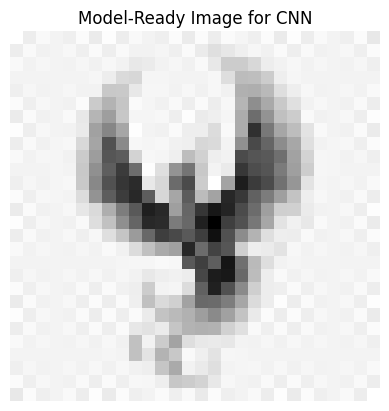

In [ ]:
import matplotlib.pyplot as plt

# 6. Display the tensor with matplotlib.pyplot.imshow
plt.imshow(model_ready_tensor[0, :, :, 0], cmap='gray')
plt.title('Model-Ready Image for CNN')
plt.axis('off')
plt.show()

Stage 8

## Answers to Tensor Comparison and Preprocessing Weakness

### 1. Comparison of `model_ready_tensor` and `expanded_channel_dim`

Both `expanded_channel_dim` (the toy (1, 3, 4, 1) tensor) and `model_ready_tensor` (the real (1, 28, 28, 1) image tensor) share a common structural format: `(batch_size, height, width, channels)`. Each has a batch size of 1 and a single channel (grayscale). A Convolutional Neural Network (CNN) could, in principle, accept both because CNN layers are designed to operate on feature maps with varying spatial dimensions (height and width), as long as the number of channels is consistent with the model's expectations.

### 2. Weakness in Preprocessing Pipeline

One weakness of the current preprocessing pipeline is how it handles non-square input images. The `img.resize((28, 28))` operation will forcefully stretch or squash the image to fit the 28x28 dimension, which can introduce distortion and negatively impact model performance by altering the aspect ratio of features. A fix would be to first pad the image to a square aspect ratio (e.g., to the larger of its width or height) before resizing, thereby preserving the original aspect ratio and preventing distortion.